# Week 4 - Learning rules - Exercises

This is an outline of the exercise only, leaving you a lot of details to fill in on your own. Later I will provide a more detailed version with some hints.

## Task 1 - Implement STDP

Implement a simulator including STDP using the efficient method from the STDP video.

## Task 2 - Competition and latency

Use your simulator to reproduce the competition and latency reduction results from this paper:

[Song et al. (2000) "Competitive Hebbian learning through spike-timing-dependent synaptic plasticity"](https://doi.org/10.1038/78829)

## Task 3 - Correlations

Use your simulator to reproduce the correlated groups results from this paper:

[Song and Abbott (2001) "Cortical Development and Remapping through Spike Timing-Dependent Plasticity"](https://doi.org/10.1016/S0896-6273(01)00451-2)

## Task 4 - Sequences (optional)

Use your simulator to reproduce the sequence learning results from this paper:

[Masquelier et al. (2008) "Spike Timing Dependent Plasticity Finds the Start of Repeating Patterns in Continuous Spike Trains"](https://doi.org/10.1371/journal.pone.0001377)

This might be quite challenging because this paper uses a different version of the STDP learning rule. For more details on how to reproduce this result, see:

[Hathway and Goodman (2018) "[Re] Spike Timing Dependent Plasticity Finds the Start of Repeating Patterns in Continuous Spike Trains"](http://neural-reckoning.org/pub_re_stdp_repeating_patterns.html)

Can you extend the results of these two papers to investigate how robust the results are to different versions of STDP, different parameters, etc.?

In [61]:
import numpy as np

In [62]:
# pre & post synaptic spikes generation
duration = 1000
dt = 10
delay = 10
num_steps = int(duration/dt)
num_neu = 2
diff = int(delay/dt)
spikes = np.zeros((num_neu, num_steps))
num_spikes = int(num_steps/10)
spikes[0, :num_spikes-1] = 1
np.random.shuffle(spikes[0, :])
for i in range (num_steps):
  if i+diff >= num_steps:
    break
  spikes[1, i+diff] = spikes[0, i]

print(spikes)

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 0.
  0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.
  1. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1.
  0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0.
  0. 1. 1. 0.]]


In [63]:
# weight update
tau_plus = 20
tau_minus = 20
a_plus = 0.01
a_minus = -0.012
a_pre = 0
a_post = 0
w = 0.1
w_history = [w]

for i in range(num_steps):
    a_pre *= np.exp(-dt / tau_plus)
    a_post *= np.exp(-dt / tau_minus)
    pre_spike = spikes[0, i] == 1
    post_spike = spikes[1, i] == 1
    if pre_spike:
        w += a_post
    if post_spike:
        w += a_pre
    if pre_spike:
        a_pre += a_plus
    if post_spike:
        a_post += a_minus
    w_history.append(w)
    print(w)

print("Initial weight:", w_history[0])
print("Final weight:", w)

0.1
0.1
0.1
0.1
0.1
0.1
0.1
0.1
0.1
0.1
0.1
0.1
0.1
0.1
0.1
0.1
0.1
0.1
0.1
0.1
0.1
0.10606530659712635
0.10606530659712635
0.10606530659712635
0.10606530659712635
0.10606530659712635
0.10606530659712635
0.10606530659712635
0.10606530659712635
0.10606530659712635
0.10606530659712635
0.10606530659712635
0.10606530659712635
0.10606530659712635
0.10606530659712635
0.10606530659712635
0.10606530659712635
0.10606530659712635
0.10606530659712635
0.10606530659712635
0.10606530659712635
0.1060647617979692
0.11213023541210343
0.11213023541210343
0.11213023541210343
0.11213023541210343
0.11050616729342601
0.11706935828382184
0.11706935828382184
0.11229242641035209
0.11982217886425017
0.11982217886425017
0.11982217886425017
0.11982217886425017
0.11982217886425017
0.11982217886425017
0.11982217886425017
0.11982217886425017
0.11982217886425017
0.11982217886425017
0.11982217886425017
0.11982217886425017
0.11982217886425017
0.11982217886425017
0.11982217886425017
0.11982217886425017
0.119822178864250

In [64]:
# LIF Neuron
def LIF(I, tau=10, threshold=1.0, reset=0.0, dt=dt):
    I = np.asarray(I, dtype=float)
    num_steps = len(I)
    V = 0.0
    V_rec = np.zeros(num_steps)
    decay = np.exp(-dt / tau)
    spikes = [] # list to store spike times
    for k in range(num_steps):
        # Record V(k * dt)
        V_rec[k] = V

        # Exact solution over one time step, assuming I[k] is constant:
        # V(t + dt) = I[k] + (V(t) - I[k]) * exp(-dt / tau)
        V = I[k] + (V - I[k]) * decay

        # Check whether the updated voltage crosses the threshold
        if V >= threshold:
            # The spike occurs at the end of the current time step
            spikes.append((k + 1) * dt)

            # Reset the membrane potential
            V = reset
    return V_rec, np.array(spikes)

In [65]:
def cur(w, spike, I0):
  I_k = np.zeros(len(spike))
  for i in range (len(spike)):
    if spike[i] == 1:
      I_k[i] = w
  I = I_k + I0
  return I
T = np.arange(num_steps)*dt*1e-3
I = cur(w, spikes[0, :], 3*np.sin(2*np.pi*10*T)**2)

V_neu1, S_neu1 = LIF(I, 10, dt=dt)
print(V_neu1)
print(S_neu1)

[0.         0.         0.65517685 0.         0.         0.65517685
 0.24102609 0.74384539 0.         0.         0.65517685 0.24102609
 0.74384539 0.         0.         0.65517685 0.24102609 0.74384539
 0.         0.         0.65517685 0.33735282 0.77928201 0.
 0.         0.65517685 0.24102609 0.74384539 0.         0.
 0.65517685 0.24102609 0.74384539 0.         0.         0.65517685
 0.24102609 0.74384539 0.         0.         0.65517685 0.24102609
 0.84017212 0.         0.         0.65517685 0.24102609 0.84017212
 0.         0.         0.75150358 0.27646272 0.75688179 0.
 0.         0.65517685 0.24102609 0.74384539 0.         0.
 0.65517685 0.24102609 0.74384539 0.         0.         0.65517685
 0.24102609 0.74384539 0.         0.         0.65517685 0.24102609
 0.74384539 0.         0.         0.65517685 0.24102609 0.74384539
 0.         0.         0.65517685 0.24102609 0.74384539 0.
 0.         0.65517685 0.24102609 0.74384539 0.         0.
 0.65517685 0.24102609 0.74384539 0.       

In [66]:

import numpy as np
import matplotlib.pyplot as plt

def LIF_STDP(spikes, dur, dt, tau_plus, tau_minus,
             a_plus, a_minus, a_pre, a_post, w, I0,
             tau, threshold=1.0, reset=0.0,
             w_min=0.0, w_max=1.0):

    num_steps = int(dur / dt)
    pre_spikes = np.asarray(spikes)
    if pre_spikes.ndim == 2:
        pre_spikes = pre_spikes[0, :]

    if len(pre_spikes) != num_steps:
        raise ValueError("Spike train length does not match duration/dt")

    I0 = np.broadcast_to(np.asarray(I0, dtype=float),
                         (num_steps,))

    w_history = [w]
    I = np.zeros(num_steps)
    V = 0.0
    V_rec = np.zeros(num_steps)
    decay = np.exp(-dt / tau)
    post_spike_times = []

    for i in range(num_steps):

        # Decay STDP traces
        a_pre *= np.exp(-dt / tau_plus)
        a_post *= np.exp(-dt / tau_minus)

        pre_spike = pre_spikes[i] == 1

        # Current uses weight before STDP update
        I[i] = w * pre_spike + I0[i]

        # LIF neuron
        V_rec[i] = V
        V = I[i] + (V - I[i]) * decay

        post_spike = V >= threshold

        if post_spike:
            post_spike_times.append((i + 1) * dt)
            V = reset

        # STDP weight updates
        if pre_spike:
            w += a_post
        if post_spike:
            w += a_pre

        # Bound the synaptic weight
        w = np.clip(w, w_min, w_max)

        # Update STDP traces
        if pre_spike:
            a_pre += a_plus
        if post_spike:
            a_post += a_minus

        w_history.append(w)

    return (
        V_rec,
        np.array(post_spike_times),
        np.array(w_history),
        I
    )


In [69]:

duration = 1000  # ms
dt = 1           # ms
num_steps = int(duration / dt)

time = np.arange(num_steps) * dt
time_w = np.arange(num_steps + 1) * dt
T = time * 1e-3

# Generate a new spike train matching the simulation
pre_spikes = np.zeros(num_steps)

# Presynaptic spikes at 10, 30, 50, ... ms
spike_times = np.arange(10, duration, 20)

spike_indices = (spike_times / dt).astype(int)
pre_spikes[spike_indices] = 1

I0 = 3 * np.sin(2 * np.pi * 10 * T)**2

tau_plus = 20
tau_minus = 20
tau = 10
w_initial = 0.1

def run_test(pre_spikes, a_plus=0.01, a_minus=-0.012,
             w=0.1, I0=I0, w_max=1.0):

    return LIF_STDP(
        pre_spikes, duration, dt,
        tau_plus, tau_minus,
        a_plus, a_minus,
        0.0, 0.0,
        w=w, I0=I0,
        tau=tau,
        w_min=0.0, w_max=w_max
    )


With input spikes: 80
Without input spikes: 80
Final weight A: 0.06841446382295009
Final weight B: 0.1


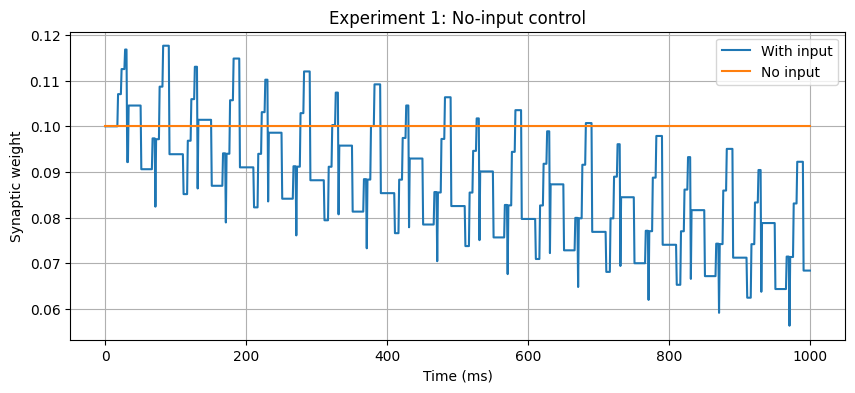

In [70]:

# A: Normal presynaptic input
V_A, S_A, W_A, I_A = run_test(pre_spikes)

# B: No presynaptic input
spikes_zero = np.zeros_like(pre_spikes)
V_B, S_B, W_B, I_B = run_test(spikes_zero)

print("With input spikes:", len(S_A))
print("Without input spikes:", len(S_B))
print("Final weight A:", W_A[-1])
print("Final weight B:", W_B[-1])

assert np.allclose(W_B, w_initial)

plt.figure(figsize=(10, 4))
plt.plot(time_w, W_A, label="With input")
plt.plot(time_w, W_B, label="No input")
plt.xlabel("Time (ms)")
plt.ylabel("Synaptic weight")
plt.title("Experiment 1: No-input control")
plt.legend()
plt.grid(True)
plt.show()


STDP enabled: 0.06841446382295009 80 spikes
STDP disabled: 0.1 80 spikes


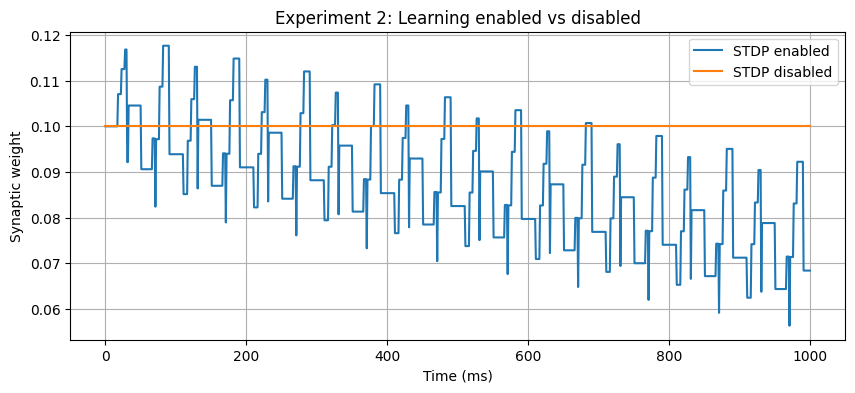

In [71]:

# STDP enabled
V_on, S_on, W_on, I_on = run_test(
    pre_spikes, a_plus=0.01, a_minus=-0.012
)

# STDP disabled
V_off, S_off, W_off, I_off = run_test(
    pre_spikes, a_plus=0.0, a_minus=0.0
)

print("STDP enabled:", W_on[-1], len(S_on), "spikes")
print("STDP disabled:", W_off[-1], len(S_off), "spikes")

assert np.allclose(W_off, w_initial)

plt.figure(figsize=(10, 4))
plt.plot(time_w, W_on, label="STDP enabled")
plt.plot(time_w, W_off, label="STDP disabled")
plt.xlabel("Time (ms)")
plt.ylabel("Synaptic weight")
plt.title("Experiment 2: Learning enabled vs disabled")
plt.legend()
plt.grid(True)
plt.show()


Small | Final weight: 0.06841 | Output spikes: 80
Medium | Final weight: 0.06037 | Output spikes: 80
Large | Final weight: 0.17812 | Output spikes: 90


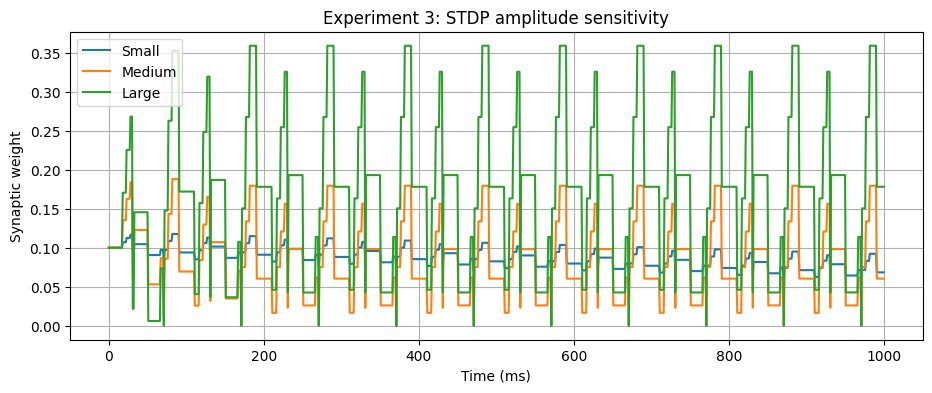

In [72]:

configs = {
    "Small": (0.01, -0.012),
    "Medium": (0.05, -0.06),
    "Large": (0.10, -0.12)
}

results = {}

plt.figure(figsize=(11, 4))

for name, (ap, am) in configs.items():
    V, S, W, I = run_test(
        pre_spikes,
        a_plus=ap,
        a_minus=am
    )

    results[name] = (V, S, W, I)

    plt.plot(time_w, W, label=name)

    print(
        name,
        "| Final weight:", round(W[-1], 5),
        "| Output spikes:", len(S)
    )

plt.xlabel("Time (ms)")
plt.ylabel("Synaptic weight")
plt.title("Experiment 3: STDP amplitude sensitivity")
plt.legend()
plt.grid(True)
plt.show()


LTP weight change: 0.006065306597126341
LTD weight change: -0.00727836791655162


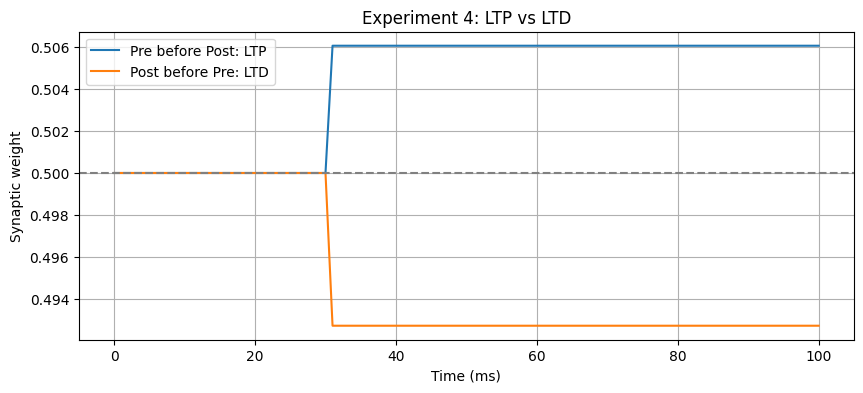

In [73]:

def test_stdp_pair(t_pre, t_post, duration=100,
                   dt=1, w=0.5):

    num_steps = int(duration / dt)
    a_pre = 0.0
    a_post = 0.0

    a_plus = 0.01
    a_minus = -0.012
    tau_plus = 20
    tau_minus = 20

    w_history = [w]

    for i in range(num_steps):
        a_pre *= np.exp(-dt / tau_plus)
        a_post *= np.exp(-dt / tau_minus)

        pre_spike = (i * dt == t_pre)
        post_spike = (i * dt == t_post)

        # Use existing traces
        if pre_spike:
            w += a_post
        if post_spike:
            w += a_pre

        # Add current spikes
        if pre_spike:
            a_pre += a_plus
        if post_spike:
            a_post += a_minus

        w_history.append(w)

    return np.array(w_history)


# Presynaptic spike first -> LTP
W_LTP = test_stdp_pair(t_pre=20, t_post=30)

# Postsynaptic spike first -> LTD
W_LTD = test_stdp_pair(t_pre=30, t_post=20)

print("LTP weight change:", W_LTP[-1] - 0.5)
print("LTD weight change:", W_LTD[-1] - 0.5)

assert W_LTP[-1] > 0.5
assert W_LTD[-1] < 0.5

plt.figure(figsize=(10, 4))

plt.plot(np.arange(len(W_LTP)), W_LTP,
         label="Pre before Post: LTP")
plt.plot(np.arange(len(W_LTD)), W_LTD,
         label="Post before Pre: LTD")

plt.axhline(0.5, color="gray", linestyle="--")
plt.xlabel("Time (ms)")
plt.ylabel("Synaptic weight")
plt.title("Experiment 4: LTP vs LTD")
plt.legend()
plt.grid(True)
plt.show()


w=0.0: 0 postsynaptic spikes
w=0.1: 0 postsynaptic spikes
w=2.0: 30 postsynaptic spikes
w=5.0: 165 postsynaptic spikes


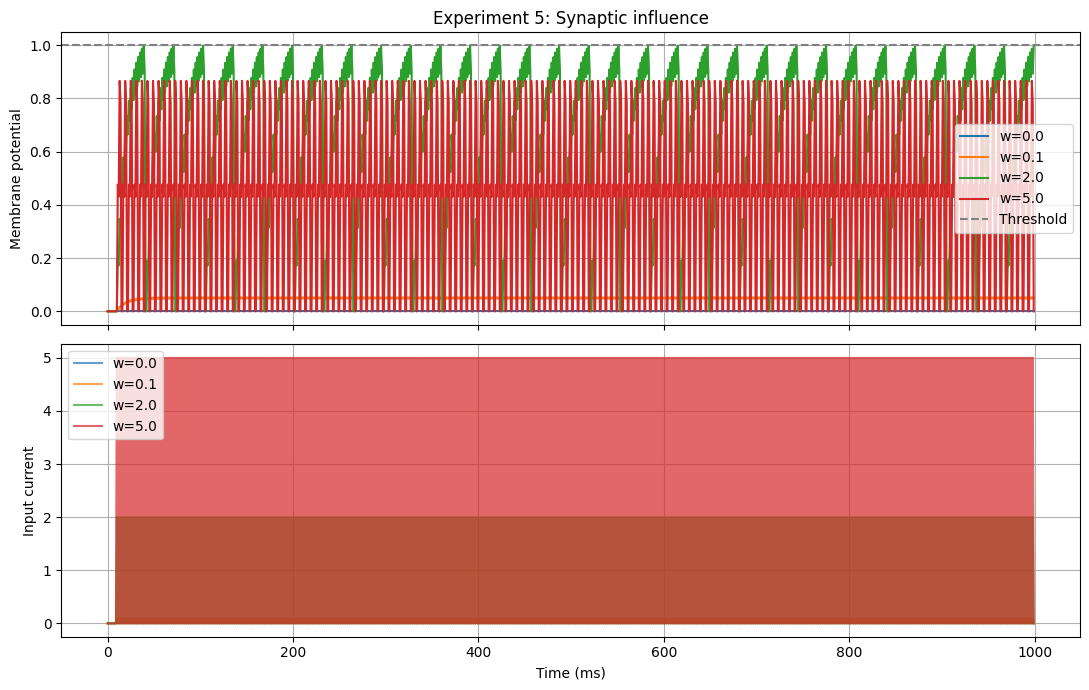

In [74]:

# Frequent input spikes for a controlled synaptic drive test
test_spikes = np.zeros(num_steps)
test_spikes[10::2] = 1  # One spike every 2 ms

zero_background = np.zeros(num_steps)

test_weights = [0.0, 0.1, 2.0, 5.0]

fig, axes = plt.subplots(2, 1, figsize=(11, 7),
                         sharex=True)

for wt in test_weights:
    V, S, W, I = run_test(
        test_spikes,
        a_plus=0.0,
        a_minus=0.0,
        w=wt,
        I0=zero_background,
        w_max=10.0
    )

    axes[0].plot(time, V, label=f"w={wt}")
    axes[1].plot(time, I, label=f"w={wt}", alpha=0.7)

    print(f"w={wt}: {len(S)} postsynaptic spikes")

axes[0].axhline(1.0, color="gray", linestyle="--",
                label="Threshold")
axes[0].set_ylabel("Membrane potential")
axes[0].set_title("Experiment 5: Synaptic influence")
axes[0].legend()
axes[0].grid(True)

axes[1].set_xlabel("Time (ms)")
axes[1].set_ylabel("Input current")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


Minimum weight: 0.0
Maximum weight: 1.0
Final weight: 0.0
Output spikes: 90


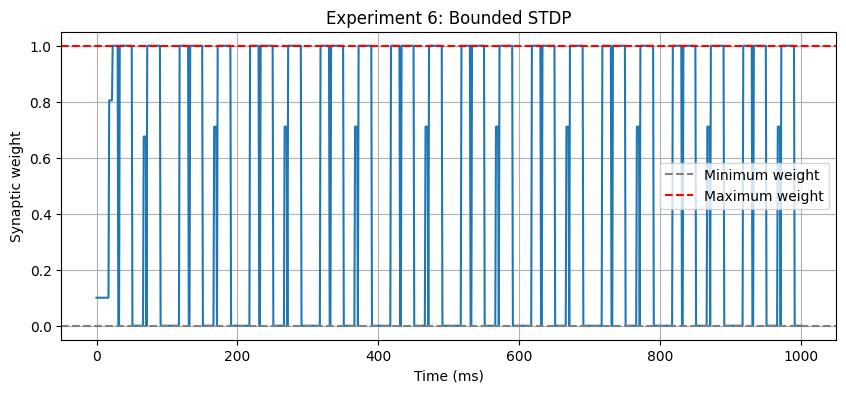

In [75]:

V_bound, S_bound, W_bound, I_bound = run_test(
    pre_spikes,
    a_plus=1.0,
    a_minus=-1.2,
    w=0.1,
    w_max=1.0
)

print("Minimum weight:", W_bound.min())
print("Maximum weight:", W_bound.max())
print("Final weight:", W_bound[-1])
print("Output spikes:", len(S_bound))

assert np.all(W_bound >= 0)
assert np.all(W_bound <= 1)

plt.figure(figsize=(10, 4))
plt.plot(time_w, W_bound)

plt.axhline(0, linestyle="--", color="gray",
            label="Minimum weight")
plt.axhline(1, linestyle="--", color="red",
            label="Maximum weight")

plt.xlabel("Time (ms)")
plt.ylabel("Synaptic weight")
plt.title("Experiment 6: Bounded STDP")
plt.legend()
plt.grid(True)
plt.show()
